In [3]:
print("Welcome to Customer Intelligence Platform V2!")

Welcome to Customer Intelligence Platform V2!


In [4]:
import pandas as pd

print("Pandas is ready!")

Pandas is ready!


In [5]:
from pathlib import Path

print(Path.cwd())

c:\Users\oades\Downloads\Downloads\customer-intelligence-platform\notebooks


In [6]:
from pathlib import Path
import pandas as pd

customers = pd.read_csv(
    Path.cwd().parent / "data" / "olist_customers_dataset.csv"
)

customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [7]:
customers.shape

(99441, 5)

In [8]:
customers["customer_unique_id"].nunique()

96096

In [9]:
customers["customer_unique_id"].isna().sum()

np.int64(0)

In [10]:
customers["customer_unique_id"].value_counts().head(10)

customer_unique_id
8d50f5eadf50201ccdcedfb9e2ac8455    17
3e43e6105506432c953e165fb2acf44c     9
1b6c7548a2a1f9037c1fd3ddfed95f33     7
6469f99c1f9dfae7733b25662e7f1782     7
ca77025e7201e3b30c44b472ff346268     7
47c1a3033b8b77b3ab6e109eb4d5fdf3     6
dc813062e0fc23409cd255f7f53c7074     6
63cfc61cee11cbe306bff5857d00bfe4     6
f0e310a6839dce9de1638e0fe5ab282a     6
de34b16117594161a6a89c50b289d35a     6
Name: count, dtype: int64

In [11]:
orders = pd.read_csv(
    Path.cwd().parent / "data" / "olist_orders_dataset.csv"
)

orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [12]:
orders.shape

(99441, 8)

In [13]:
orders["order_id"].duplicated().sum()

np.int64(0)

In [14]:
customers["customer_id"].duplicated().sum()

np.int64(0)

In [15]:
customer_orders = orders.merge(
    customers,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

customer_orders.shape

(99441, 12)

In [16]:
customer_orders["customer_unique_id"].isna().sum()

np.int64(0)

In [17]:
customer_orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [18]:
delivered_orders = customer_orders[
    customer_orders["order_status"] == "delivered"
]

delivered_orders["customer_unique_id"].nunique()

93358

In [19]:
delivered_orders["order_purchase_timestamp"].isna().sum()

np.int64(0)

In [20]:
payments = pd.read_csv(
    Path.cwd().parent / "data" / "olist_order_payments_dataset.csv"
)

orders_without_payments = delivered_orders[
    ~delivered_orders["order_id"].isin(payments["order_id"])
]

orders_without_payments[
    ["order_id", "customer_unique_id", "order_status"]
]

,order_id,customer_unique_id,order_status
30710,bfbd0f9bdef84302105ad712db648a6c,830d5b7aaa3b6f1e9ad63703bec97d23,delivered


In [21]:
customer_id_to_check = "830d5b7aaa3b6f1e9ad63703bec97d23"

delivered_orders[
    delivered_orders["customer_unique_id"] == customer_id_to_check
][["order_id", "customer_unique_id", "order_status"]]

,order_id,customer_unique_id,order_status
30710,bfbd0f9bdef84302105ad712db648a6c,830d5b7aaa3b6f1e9ad63703bec97d23,delivered


In [22]:
delivered_with_payments = delivered_orders[
    delivered_orders["order_id"].isin(payments["order_id"])
]

print(
    "Unique delivered customers with payments:",
    delivered_with_payments["customer_unique_id"].nunique()
)

Unique delivered customers with payments: 93357


### Customer Count Reconciliation

The raw Olist dataset contains 96,096 distinct customers. Of these, 93,358 have at least one delivered order.

After requiring a matching payment record, the population decreases to 93,357 distinct customers, matching the Power BI dashboard.

The discrepancy was traced to one delivered order without a matching payment record. The associated customer had no other delivered orders.

**Key takeaway:** Customer counts depend on the population definition and join conditions. Reporting metrics must use consistent definitions to support meaningful comparisons.

In [23]:
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [24]:
orders.loc[
    orders["order_delivered_customer_date"].isna(),
    "order_status"
].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [25]:
orders.loc[
    (orders["order_status"] == "delivered")
    & (orders["order_delivered_customer_date"].isna()),
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date"
    ]
]

,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:07,NaN
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:43,NaN
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-01 17:05:11,NaN
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-01 22:05:55,NaN
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-01 21:14:02,NaN
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:22:43,NaN
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-08 12:09:39,NaN
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-06-27 16:09:12,NaN


### Missing Delivery Date Investigation

The orders dataset contains 2,965 records without a customer delivery date. Most belong to orders not marked as delivered.

However, eight orders are marked as delivered despite having no recorded customer delivery date.

**Analytical decision:** Retain these records for purchase-behaviour analysis because their purchase timestamps and delivered statuses are available. Exclude them from calculations requiring an actual customer delivery date, while reporting the number excluded.

**Key takeaway:** Missing values should be investigated in their business context rather than automatically deleted or replaced.

In [26]:
orders.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [27]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

orders["order_purchase_timestamp"].dtype

dtype('<M8[us]')

In [28]:
orders["order_purchase_timestamp"].isna().sum()

np.int64(0)

In [29]:
date_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

orders[date_columns].dtypes

order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [30]:
orders[date_columns].isna().sum()

order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [31]:
print("First order date:", orders["order_purchase_timestamp"].min())

print("Last order date:", orders["order_purchase_timestamp"].max())

First order date: 2016-09-04 21:15:19
Last order date: 2018-10-17 17:30:18


In [32]:
monthly_orders = (
    orders
    .groupby(orders["order_purchase_timestamp"].dt.to_period("M"))
    .size()
)

monthly_orders

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64

In [33]:
from PIL import Image

print("Pillow is working!")

Pillow is working!


In [34]:
import matplotlib.pyplot as plt

print("Matplotlib is working!")

Matplotlib is working!


In [35]:
import matplotlib
print(matplotlib.__version__)
print(matplotlib.__file__)

3.11.2
c:\Users\oades\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\matplotlib\__init__.py


In [36]:
import matplotlib.pyplot as plt

print("Matplotlib plotting is ready!")

Matplotlib plotting is ready!


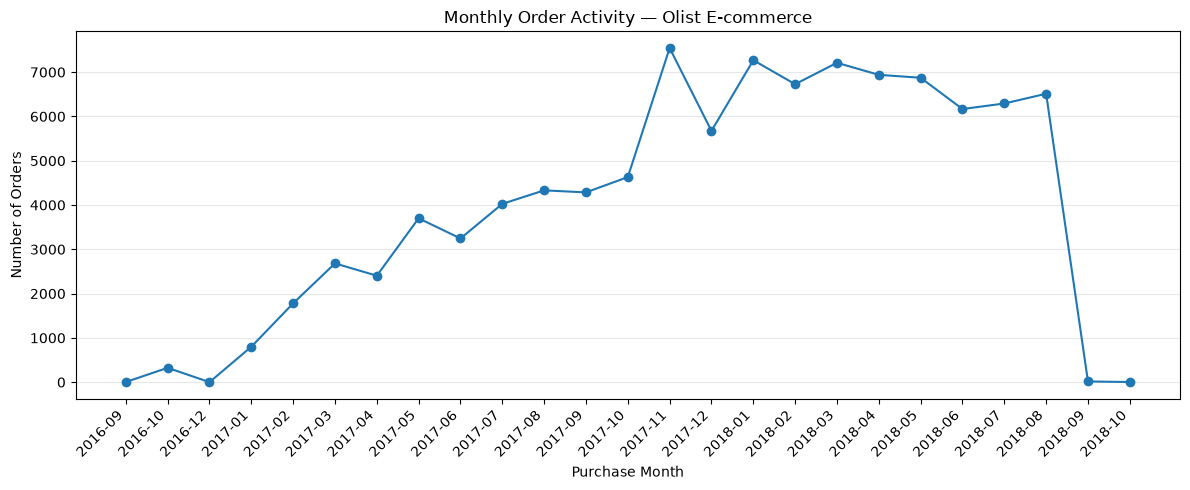

In [37]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_orders.index.astype(str),
    monthly_orders.values,
    marker="o"
)

plt.title("Monthly Order Activity — Olist E-commerce")
plt.xlabel("Purchase Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
orders.loc[
    orders["order_purchase_timestamp"] >= "2018-09-01",
    "order_status"
].value_counts()

order_status
canceled    19
shipped      1
Name: count, dtype: int64

In [39]:
delivered_monthly = (
    orders[orders["order_status"] == "delivered"]
    .groupby(orders["order_purchase_timestamp"].dt.to_period("M"))
    .size()
)

delivered_monthly.tail(6)

order_purchase_timestamp
2018-03    7003
2018-04    6798
2018-05    6749
2018-06    6099
2018-07    6159
2018-08    6351
Freq: M, dtype: int64

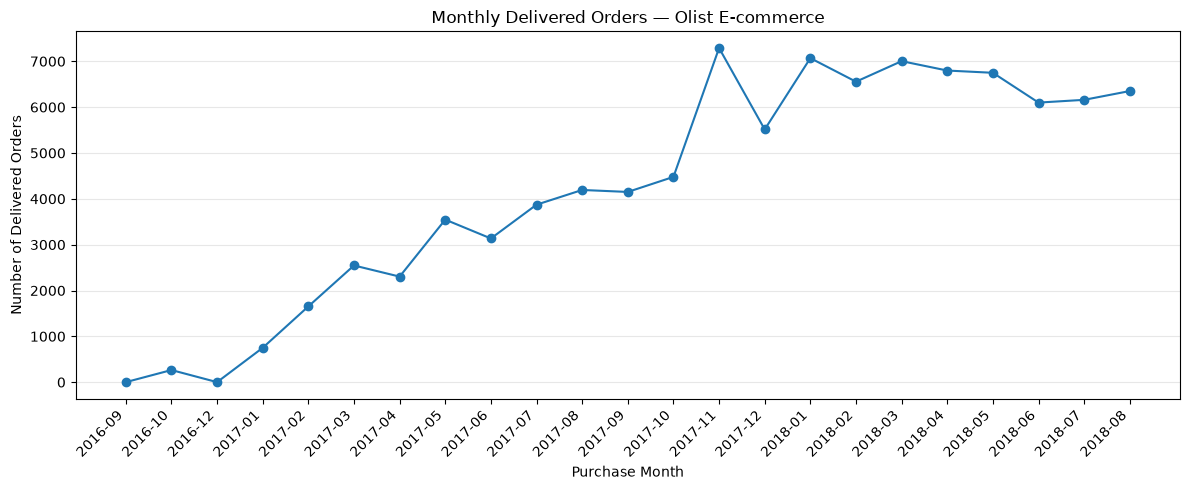

In [40]:
plt.figure(figsize=(12, 5))

plt.plot(
    delivered_monthly.index.astype(str),
    delivered_monthly.values,
    marker="o"
)

plt.title("Monthly Delivered Orders — Olist E-commerce")
plt.xlabel("Purchase Month")
plt.ylabel("Number of Delivered Orders")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [41]:
print("Busiest month:", delivered_monthly.idxmax())
print("Delivered orders:", delivered_monthly.max())

Busiest month: 2017-11
Delivered orders: 7289


### Monthly Order Activity — Key Findings

The Olist dataset contains order purchases recorded between September 2016 and October 2018.

**Key findings:**

- Delivered-order activity generally increased throughout 2017.
- November 2017 recorded the highest monthly delivered-order count, with **7,289 orders**.
- Monthly delivered-order volumes remained relatively stable between March and August 2018, ranging from 6,099 to 7,003.
- September and October 2018 contained only 20 orders, of which 19 were cancelled and one was shipped. No orders from those months were marked as delivered.

**Analytical decision:** Use delivered orders when analysing completed purchasing activity. Group orders by their purchase month rather than their delivery month.

**Limitation:** The dataset's early and final months may not represent complete periods of normal business activity. The November peak cannot be attributed to a particular promotion without further evidence.

In [42]:
customer_frequency = (
    delivered_orders
    .groupby("customer_unique_id")["order_id"]
    .nunique()
)

customer_frequency.head(10)

customer_unique_id
0000366f3b9a7992bf8c76cfdf3221e2    1
0000b849f77a49e4a4ce2b2a4ca5be3f    1
0000f46a3911fa3c0805444483337064    1
0000f6ccb0745a6a4b88665a16c9f078    1
0004aac84e0df4da2b147fca70cf8255    1
0004bd2a26a76fe21f786e4fbd80607f    1
00050ab1314c0e55a6ca13cf7181fecf    1
00053a61a98854899e70ed204dd4bafe    1
0005e1862207bf6ccc02e4228effd9a0    1
0005ef4cd20d2893f0d9fbd94d3c0d97    1
Name: order_id, dtype: int64

In [43]:
purchase_frequency_distribution = (
    customer_frequency
    .value_counts()
    .sort_index()
)

purchase_frequency_distribution

order_id
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

In [44]:
one_time_customers = (customer_frequency == 1).sum()

repeat_customers = (customer_frequency >= 2).sum()

print("One-time customers:", one_time_customers)
print("Repeat customers:", repeat_customers)

One-time customers: 90557
Repeat customers: 2801


In [45]:
repeat_customer_rate = (
    repeat_customers / customer_frequency.nunique()
)

In [46]:
repeat_customer_rate = (
    repeat_customers / len(customer_frequency)
) * 100

print(f"Repeat Customer Rate: {repeat_customer_rate:.2f}%")

Repeat Customer Rate: 3.00%


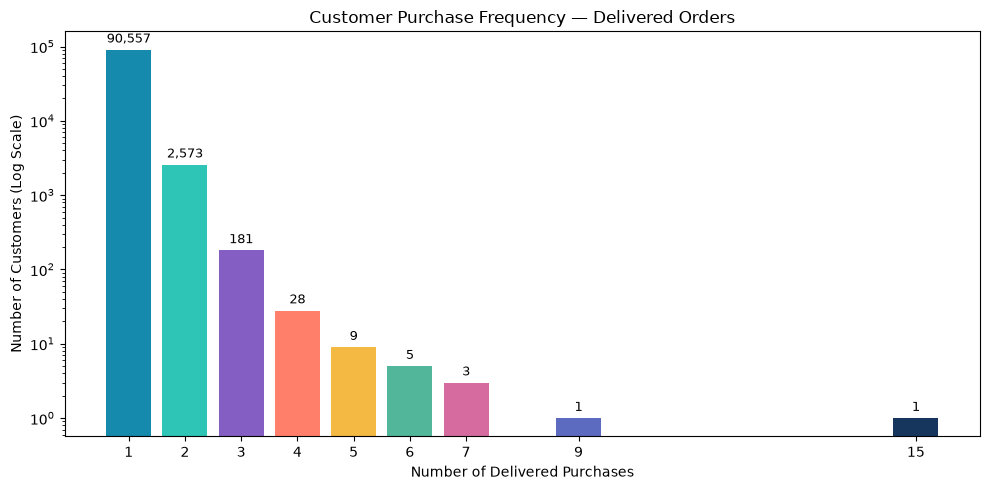

In [51]:
bar_colors = [
    "#168AAD",
    "#2EC4B6",
    "#845EC2",
    "#FF7F6A",
    "#F4B942",
    "#52B69A",
    "#D66BA0",
    "#5C6BC0",
    "#17365D"
]

plt.figure(figsize=(10, 5))

bars = plt.bar(
    purchase_frequency_distribution.index,
    purchase_frequency_distribution.values,
    color=bar_colors
)

plt.bar_label(
    bars,
    labels=[f"{value:,}" for value in purchase_frequency_distribution.values],
    padding=3,
    fontsize=9
)

plt.title("Customer Purchase Frequency — Delivered Orders")
plt.xlabel("Number of Delivered Purchases")
plt.ylabel("Number of Customers (Log Scale)")

plt.xticks(purchase_frequency_distribution.index)
plt.yscale("log")
plt.grid(False)

plt.tight_layout()
plt.show()

### Customer Purchase Frequency — Key Findings

The analysis examines customer purchasing frequency using delivered orders from the Brazilian Olist e-commerce dataset.

**Key findings:**

- **93,358 unique customers** made at least one delivered purchase.
- **90,557 customers** made exactly one delivered purchase.
- **2,801 customers** made two or more delivered purchases.
- The observed repeat-customer rate was **3.00%**.
- The highest recorded purchase frequency was **15 delivered orders** for one customer.

**Business interpretation:**

The dataset shows that one-time purchasing dominates observed customer behaviour. This suggests that understanding repeat-purchase opportunities could be valuable for customer retention planning.

However, the low observed repeat-purchase rate does not establish why customers failed to return.

**Analytical considerations:**

- Only delivered orders were included.
- Customers who purchased near the end of the dataset had less time to make another purchase.
- The chart uses a logarithmic vertical axis to make smaller purchase-frequency groups visible.
- The spending-based Power BI dashboard contains one fewer one-time customer because one delivered order lacks a matching payment record.

**Key takeaway:** Repeat purchasing is relatively uncommon within the observed dataset, making customer retention an important area for further investigation.

In [52]:
customer_orders["order_purchase_timestamp"].dtype

<StringDtype(storage='python', na_value=nan)>

In [53]:
customer_orders["order_purchase_timestamp"] = pd.to_datetime(
    customer_orders["order_purchase_timestamp"],
    errors="coerce"
)

customer_orders["order_purchase_timestamp"].dtype

dtype('<M8[us]')

In [54]:
customer_orders["order_purchase_timestamp"].isna().sum()

np.int64(0)

In [55]:
customer_purchase_history = (
    customer_orders[
        customer_orders["order_status"] == "delivered"
    ]
    .sort_values(
        ["customer_unique_id", "order_purchase_timestamp", "order_id"]
    )
    .copy()
)

customer_purchase_history[
    ["customer_unique_id", "order_id", "order_purchase_timestamp"]
].head(10)

,customer_unique_id,order_id,order_purchase_timestamp
52798,0000366f3b9a7992bf8c76cfdf3221e2,e22acc9c116caa3f2b7121bbb380d08e,2018-05-10 10:56:27
73889,0000b849f77a49e4a4ce2b2a4ca5be3f,3594e05a005ac4d06a72673270ef9ec9,2018-05-07 11:11:27
26460,0000f46a3911fa3c0805444483337064,b33ec3b699337181488304f362a6b734,2017-03-10 21:05:03
98493,0000f6ccb0745a6a4b88665a16c9f078,41272756ecddd9a9ed0180413cc22fb6,2017-10-12 20:29:41
41564,0004aac84e0df4da2b147fca70cf8255,d957021f1127559cd947b62533f484f7,2017-11-14 19:45:42
78514,0004bd2a26a76fe21f786e4fbd80607f,3e470077b690ea3e3d501cffb5e0c499,2018-04-05 19:33:16
74715,00050ab1314c0e55a6ca13cf7181fecf,d0028facea13f508e880202d7097a5a1,2018-04-20 12:57:23
6867,00053a61a98854899e70ed204dd4bafe,44e608f2db00c74a1fe329de44416a4e,2018-02-28 11:15:41
71235,0005e1862207bf6ccc02e4228effd9a0,ae76bef74b97bcb0b3e355e60d9a6f9c,2017-03-04 23:32:12
68876,0005ef4cd20d2893f0d9fbd94d3c0d97,01b330808c5819a6a3cb79b72f0b8288,2018-03-12 15:22:12


In [56]:
customer_purchase_history["purchase_number"] = (
    customer_purchase_history
    .groupby("customer_unique_id")
    .cumcount() + 1
)

customer_purchase_history[
    [
        "customer_unique_id",
        "order_purchase_timestamp",
        "purchase_number"
    ]
].head(10)

,customer_unique_id,order_purchase_timestamp,purchase_number
52798,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1
73889,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1
26460,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1
98493,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1
41564,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1
78514,0004bd2a26a76fe21f786e4fbd80607f,2018-04-05 19:33:16,1
74715,00050ab1314c0e55a6ca13cf7181fecf,2018-04-20 12:57:23,1
6867,00053a61a98854899e70ed204dd4bafe,2018-02-28 11:15:41,1
71235,0005e1862207bf6ccc02e4228effd9a0,2017-03-04 23:32:12,1
68876,0005ef4cd20d2893f0d9fbd94d3c0d97,2018-03-12 15:22:12,1


In [57]:
second_purchases = customer_purchase_history[
    customer_purchase_history["purchase_number"] == 2
]

print("Customers with a second purchase:", len(second_purchases))

Customers with a second purchase: 2801


In [58]:
customer_purchase_history["previous_purchase_date"] = (
    customer_purchase_history
    .groupby("customer_unique_id")["order_purchase_timestamp"]
    .shift(1)
)

customer_purchase_history[
    [
        "customer_unique_id",
        "purchase_number",
        "order_purchase_timestamp",
        "previous_purchase_date"
    ]
].loc[
    customer_purchase_history["purchase_number"] == 2
].head(10)

,customer_unique_id,purchase_number,order_purchase_timestamp,previous_purchase_date
40042,004288347e5e88a27ded2bb23747066c,2,2018-01-14 07:36:54,2017-07-27 14:13:03
90040,00a39521eb40f7012db50455bf083460,2,2018-06-03 10:12:57,2018-05-23 20:14:21
84191,00cc12a6d8b578b8ebd21ea4e2ae8b27,2,2017-03-21 19:25:23,2017-03-21 19:25:22
49369,011575986092c30523ecb71ff10cb473,2,2018-04-18 21:58:08,2018-02-17 15:54:49
12466,011b4adcd54683b480c4d841250a987f,2,2018-02-15 11:40:57,2017-08-22 12:51:29
12329,012452d40dafae4df401bced74cdb490,2,2018-05-14 12:12:45,2017-06-18 22:46:42
46106,012a218df8995d3ec3bb221828360c86,2,2018-06-18 13:08:38,2018-05-07 10:28:17
73134,013ef03e0f3f408dd9bf555e4edcdc0a,2,2018-07-20 04:13:54,2018-06-21 04:46:11
34799,013f4353d26bb05dc6652f1269458d8d,2,2017-11-28 13:30:58,2017-11-24 13:33:20
98778,015557c9912277312b9073947804a7ba,2,2017-05-01 14:48:33,2017-03-23 22:45:46


In [59]:
second_purchases = customer_purchase_history[
    customer_purchase_history["purchase_number"] == 2
].copy()

second_purchases["days_to_second_purchase"] = (
    (
        second_purchases["order_purchase_timestamp"]
        - second_purchases["previous_purchase_date"]
    ).dt.total_seconds() / 86400
)

second_purchases[
    [
        "order_purchase_timestamp",
        "previous_purchase_date",
        "days_to_second_purchase"
    ]
].head(10)

,order_purchase_timestamp,previous_purchase_date,days_to_second_purchase
40042,2018-01-14 07:36:54,2017-07-27 14:13:03,170.724896
90040,2018-06-03 10:12:57,2018-05-23 20:14:21,10.582361
84191,2017-03-21 19:25:23,2017-03-21 19:25:22,0.000012
49369,2018-04-18 21:58:08,2018-02-17 15:54:49,60.252303
12466,2018-02-15 11:40:57,2017-08-22 12:51:29,176.951019
12329,2018-05-14 12:12:45,2017-06-18 22:46:42,329.559757
46106,2018-06-18 13:08:38,2018-05-07 10:28:17,42.111354
73134,2018-07-20 04:13:54,2018-06-21 04:46:11,28.977581
34799,2017-11-28 13:30:58,2017-11-24 13:33:20,3.998356
98778,2017-05-01 14:48:33,2017-03-23 22:45:46,38.668600


In [60]:
average_days = second_purchases["days_to_second_purchase"].mean()

median_days = second_purchases["days_to_second_purchase"].median()

print(f"Average days to second purchase: {average_days:.2f}")
print(f"Median days to second purchase: {median_days:.2f}")

Average days to second purchase: 81.21
Median days to second purchase: 28.98


In [61]:
print(
    "Shortest time (days):",
    round(second_purchases["days_to_second_purchase"].min(), 2)
)

print(
    "Longest time (days):",
    round(second_purchases["days_to_second_purchase"].max(), 2)
)

Shortest time (days): 0.0
Longest time (days): 608.98


In [62]:
second_purchases["days_to_second_purchase"].describe()

count    2801.000000
mean       81.206685
std       110.004017
min         0.000000
25%         0.002130
50%        28.980197
75%       126.263588
max       608.978912
Name: days_to_second_purchase, dtype: float64

In [63]:
rapid_repeat_customers = (
    second_purchases["days_to_second_purchase"] < 1
).sum()

print("Second purchases within 24 hours:", rapid_repeat_customers)

Second purchases within 24 hours: 853


In [64]:
within_one_hour = (
    second_purchases["days_to_second_purchase"] < (1 / 24)
).sum()

print("Second purchases within one hour:", within_one_hour)

Second purchases within one hour: 797


In [65]:
within_five_minutes = (
    second_purchases["days_to_second_purchase"] < (5 / 1440)
).sum()

print("Second purchases within five minutes:", within_five_minutes)

Second purchases within five minutes: 713


In [66]:
rapid_purchase_groups = {
    "Under 5 minutes": within_five_minutes,
    "5 minutes–1 hour": within_one_hour - within_five_minutes,
    "1–24 hours": rapid_repeat_customers - within_one_hour,
    "Over 24 hours": len(second_purchases) - rapid_repeat_customers
}

rapid_purchase_groups

{'Under 5 minutes': np.int64(713),
 '5 minutes–1 hour': np.int64(84),
 '1–24 hours': np.int64(56),
 'Over 24 hours': np.int64(1948)}

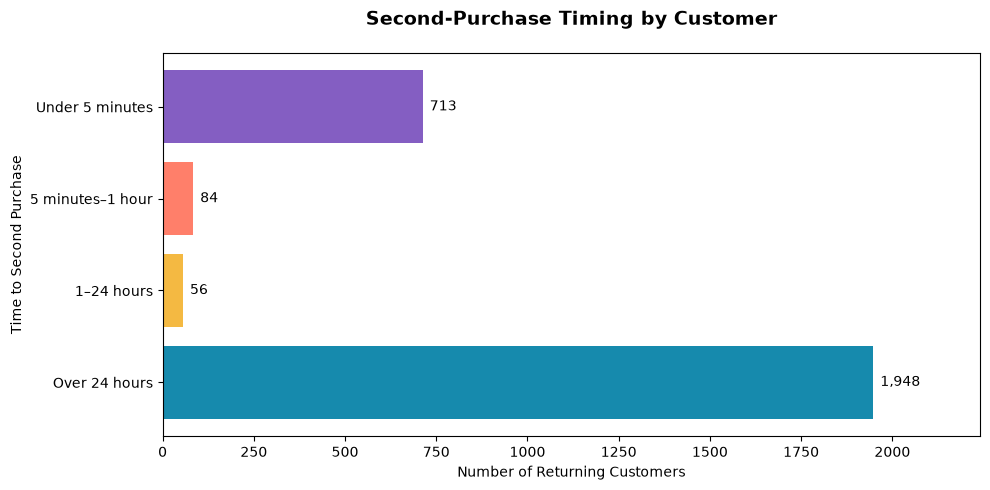

In [68]:
labels = list(rapid_purchase_groups.keys())
values = list(rapid_purchase_groups.values())

colors = [
    "#845EC2",  # Purple
    "#FF7F6A",  # Coral
    "#F4B942",  # Gold
    "#168AAD"   # Teal
]

plt.figure(figsize=(10, 5))

bars = plt.barh(
    labels,
    values,
    color=colors
)

plt.bar_label(
    bars,
    labels=[f"{value:,}" for value in values],
    padding=5
)

plt.title(
    "Second-Purchase Timing by Customer",
    fontsize=14,
    fontweight="bold",
    pad=20
)
plt.xlabel("Number of Returning Customers")
plt.ylabel("Time to Second Purchase")

plt.gca().invert_yaxis()
plt.grid(False)
plt.xlim(0, max(values) * 1.15)

plt.tight_layout()
plt.show()

### Rapid Repeat-Purchase Analysis — Key Findings

This analysis examines the time between customers' first and second delivered purchases in the Olist e-commerce dataset.

**Key findings**

- **2,801 customers** made at least two delivered purchases.
- **713 customers (25.5%)** placed their second order within five minutes.
- **797 customers (28.5%)** placed their second order within one hour.
- **853 customers (30.5%)** placed their second order within 24 hours.
- **1,948 customers (69.5%)** took more than 24 hours to place their second order.

**Business interpretation**

A substantial proportion of second purchases occurred shortly after the first purchase. Some may represent multiple orders placed during the same shopping session rather than customers returning on a separate occasion.

This distinction matters because repeat-order frequency and longer-term customer retention are not necessarily equivalent.

**Analytical limitations**

- The analysis includes delivered orders only.
- Purchase timestamps indicate when orders were placed, but do not establish whether they occurred within the same shopping session.
- The existing 3.00% repeat-customer rate remains valid under its current definition.
- A future analysis could introduce a minimum time interval between purchases to examine longer-term return behaviour.

**Key takeaway:** Measuring customer retention requires clearly defining what constitutes a meaningful return purchase.

In [69]:
customers_returning_after_24h = (
    second_purchases["days_to_second_purchase"] >= 1
).sum()

return_rate_after_24h = (
    customers_returning_after_24h / len(customer_frequency)
) * 100

print("Customers returning after 24 hours:", customers_returning_after_24h)
print(f"Return rate after 24 hours: {return_rate_after_24h:.2f}%")

Customers returning after 24 hours: 1948
Return rate after 24 hours: 2.09%


In [70]:
customers_with_3plus_orders = (
    customer_frequency >= 3
).sum()

print(
    "Customers with 3 or more delivered purchases:",
    customers_with_3plus_orders
)

Customers with 3 or more delivered purchases: 228


In [71]:
rapid_customer_ids = second_purchases.loc[
    second_purchases["days_to_second_purchase"] < 1,
    "customer_unique_id"
]

print("Customers with a rapid second purchase:", len(rapid_customer_ids))

Customers with a rapid second purchase: 853


In [72]:
third_purchases = customer_purchase_history[
    (customer_purchase_history["customer_unique_id"].isin(rapid_customer_ids))
    & (customer_purchase_history["purchase_number"] == 3)
]

print(
    "Rapid-repeat customers with a third purchase:",
    len(third_purchases)
)

Rapid-repeat customers with a third purchase: 69


In [73]:
first_purchase_dates = (
    customer_purchase_history[
        customer_purchase_history["purchase_number"] == 1
    ]
    .set_index("customer_unique_id")["order_purchase_timestamp"]
)

third_purchases = third_purchases.copy()

third_purchases["days_first_to_third"] = (
    third_purchases["order_purchase_timestamp"]
    - third_purchases["customer_unique_id"].map(first_purchase_dates)
).dt.total_seconds() / 86400

third_purchases[
    ["customer_unique_id", "days_first_to_third"]
].head(10)

,customer_unique_id,days_first_to_third
59312,06a52782a04f0086d16b9c22d0e29438,0.000012
23205,0a61b571f594b6919601bcf3380da7f7,154.028623
48587,0e4cb268bd62da7db135af6349b4fc2a,0.308056
81491,12f5d6e1cbf93dafd9dcc19095df0b3d,0.004063
39813,18a65d67bb184e736656cc017f09f7b8,51.017245
80664,25a560b9a6006157838aab1bdbd68624,0.989074
12362,25f3cf83109f636d52d288fa4e797111,0.000012
15948,2b161eaf4956b131691842e87b3c39c7,13.940683
42203,2e43e031f10de28e557c35ef668f9396,0.000012
53218,33176de67c05eeed870fd49f234387a0,102.333333


In [74]:
later_third_purchases = (
    third_purchases["days_first_to_third"] >= 1
).sum()

print(
    "Rapid-repeat customers with a third purchase after 24 hours:",
    later_third_purchases
)

Rapid-repeat customers with a third purchase after 24 hours: 38


In [75]:
first_purchase_dates = (
    customer_purchase_history
    .groupby("customer_unique_id")["order_purchase_timestamp"]
    .transform("min")
)

customer_purchase_history["days_since_first_purchase"] = (
    (
        customer_purchase_history["order_purchase_timestamp"]
        - first_purchase_dates
    ).dt.total_seconds() / 86400
)

customers_returning_after_24h_any_order = (
    customer_purchase_history.loc[
        customer_purchase_history["days_since_first_purchase"] >= 1,
        "customer_unique_id"
    ].nunique()
)

print(
    "Customers with any later purchase after 24 hours:",
    customers_returning_after_24h_any_order
)

Customers with any later purchase after 24 hours: 1993


In [76]:
refined_return_rate = (
    customers_returning_after_24h_any_order
    / len(customer_frequency)
) * 100

print(f"24-hour return rate (any later order): {refined_return_rate:.2f}%")

24-hour return rate (any later order): 2.13%


### Refined Customer Return Analysis — 24-Hour Threshold

This analysis investigates whether customers placed an additional delivered order at least 24 hours after their first purchase.

**Key findings**

- **93,358 customers** had at least one delivered order.
- **2,801 customers (3.00%)** made at least two delivered purchases.
- **1,948 customers (2.09%)** made their second purchase at least 24 hours after their first.
- **1,993 customers (2.13%)** made at least one subsequent purchase at least 24 hours after their first.
- Considering all subsequent purchases identified **45 additional customers** who were not captured by the second-purchase-only measure.

**Business interpretation**

The conventional repeat-customer rate measures order frequency, while the refined 24-hour return measure distinguishes customers who made another purchase after a minimum elapsed period.

The refined measure may provide a useful complementary perspective when investigating longer-term purchasing behaviour.

**Limitations**

- Only delivered orders were included.
- The 24-hour threshold is an analytical assumption, not a verified shopping-session boundary.
- The dataset's limited observation period affects opportunities to observe subsequent purchases.
- Neither metric independently establishes customer satisfaction, loyalty or the effectiveness of retention initiatives.

**Key takeaway:** Customer retention should be assessed using clearly defined measures that distinguish repeat-order frequency from purchasing behaviour over time.

In [77]:
customer_purchase_history["first_purchase_month"] = (
    customer_purchase_history
    .groupby("customer_unique_id")["order_purchase_timestamp"]
    .transform("min")
    .dt.to_period("M")
)

customer_purchase_history[
    [
        "customer_unique_id",
        "order_purchase_timestamp",
        "first_purchase_month"
    ]
].head(10)

,customer_unique_id,order_purchase_timestamp,first_purchase_month
52798,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,2018-05
73889,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,2018-05
26460,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,2017-03
98493,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,2017-10
41564,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,2017-11
78514,0004bd2a26a76fe21f786e4fbd80607f,2018-04-05 19:33:16,2018-04
74715,00050ab1314c0e55a6ca13cf7181fecf,2018-04-20 12:57:23,2018-04
6867,00053a61a98854899e70ed204dd4bafe,2018-02-28 11:15:41,2018-02
71235,0005e1862207bf6ccc02e4228effd9a0,2017-03-04 23:32:12,2017-03
68876,0005ef4cd20d2893f0d9fbd94d3c0d97,2018-03-12 15:22:12,2018-03


In [78]:
cohort_sizes = (
    customer_purchase_history
    .groupby("first_purchase_month")["customer_unique_id"]
    .nunique()
    .sort_index()
)

cohort_sizes

first_purchase_month
2016-09       1
2016-10     262
2016-12       1
2017-01     717
2017-02    1628
2017-03    2503
2017-04    2256
2017-05    3451
2017-06    3037
2017-07    3752
2017-08    4057
2017-09    4004
2017-10    4328
2017-11    7060
2017-12    5338
2018-01    6842
2018-02    6288
2018-03    6774
2018-04    6582
2018-05    6506
2018-06    5878
2018-07    5949
2018-08    6144
Freq: M, Name: customer_unique_id, dtype: int64

In [79]:
cohort_repeat_customers = (
    customer_purchase_history[
        customer_purchase_history["purchase_number"] == 2
    ]
    .groupby("first_purchase_month")["customer_unique_id"]
    .nunique()
    .sort_index()
)

cohort_repeat_customers

first_purchase_month
2016-10     12
2016-12      1
2017-01     52
2017-02     66
2017-03    121
2017-04    102
2017-05    182
2017-06    161
2017-07    175
2017-08    191
2017-09    180
2017-10    160
2017-11    223
2017-12    139
2018-01    208
2018-02    236
2018-03    162
2018-04    129
2018-05    109
2018-06     70
2018-07     88
2018-08     34
Freq: M, Name: customer_unique_id, dtype: int64

In [80]:
cohort_repeat_rate = (
    cohort_repeat_customers
    .div(cohort_sizes)
    .mul(100)
    .fillna(0)
)

cohort_repeat_rate.round(2)

first_purchase_month
2016-09      0.00
2016-10      4.58
2016-12    100.00
2017-01      7.25
2017-02      4.05
2017-03      4.83
2017-04      4.52
2017-05      5.27
2017-06      5.30
2017-07      4.66
2017-08      4.71
2017-09      4.50
2017-10      3.70
2017-11      3.16
2017-12      2.60
2018-01      3.04
2018-02      3.75
2018-03      2.39
2018-04      1.96
2018-05      1.68
2018-06      1.19
2018-07      1.48
2018-08      0.55
Freq: M, Name: customer_unique_id, dtype: float64

In [81]:
second_purchases["returned_within_30_days"] = (
    (second_purchases["days_to_second_purchase"] <= 30)
    & (second_purchases["days_to_second_purchase"] > 0)
)

second_purchases["returned_within_30_days"].value_counts()

returned_within_30_days
False    1642
True     1159
Name: count, dtype: int64

In [82]:
second_purchases["first_purchase_month"] = (
    second_purchases["customer_unique_id"]
    .map(
        customer_purchase_history
        .groupby("customer_unique_id")["first_purchase_month"]
        .first()
    )
)

second_purchases[
    [
        "customer_unique_id",
        "first_purchase_month",
        "returned_within_30_days"
    ]
].head(10)

,customer_unique_id,first_purchase_month,returned_within_30_days
40042,004288347e5e88a27ded2bb23747066c,2017-07,False
90040,00a39521eb40f7012db50455bf083460,2018-05,True
84191,00cc12a6d8b578b8ebd21ea4e2ae8b27,2017-03,True
49369,011575986092c30523ecb71ff10cb473,2018-02,False
12466,011b4adcd54683b480c4d841250a987f,2017-08,False
12329,012452d40dafae4df401bced74cdb490,2017-06,False
46106,012a218df8995d3ec3bb221828360c86,2018-05,False
73134,013ef03e0f3f408dd9bf555e4edcdc0a,2018-06,True
34799,013f4353d26bb05dc6652f1269458d8d,2017-11,True
98778,015557c9912277312b9073947804a7ba,2017-03,False


In [83]:
observation_end = pd.Timestamp("2018-08-31 23:59:59")

first_purchases = customer_purchase_history[
    customer_purchase_history["purchase_number"] == 1
].copy()

first_purchases["has_30_day_followup"] = (
    first_purchases["order_purchase_timestamp"]
    + pd.Timedelta(days=30)
    <= observation_end
)

first_purchases["has_30_day_followup"].value_counts()

has_30_day_followup
True     87508
False     5850
Name: count, dtype: int64

In [84]:
eligible_cohort_sizes = (
    first_purchases[
        first_purchases["has_30_day_followup"]
    ]
    .groupby("first_purchase_month")["customer_unique_id"]
    .nunique()
    .sort_index()
)

eligible_cohort_sizes

first_purchase_month
2016-09       1
2016-10     262
2016-12       1
2017-01     717
2017-02    1628
2017-03    2503
2017-04    2256
2017-05    3451
2017-06    3037
2017-07    3752
2017-08    4057
2017-09    4004
2017-10    4328
2017-11    7060
2017-12    5338
2018-01    6842
2018-02    6288
2018-03    6774
2018-04    6582
2018-05    6506
2018-06    5878
2018-07    5949
2018-08     294
Freq: M, Name: customer_unique_id, dtype: int64

In [85]:
eligible_customer_ids = first_purchases.loc[
    first_purchases["has_30_day_followup"],
    "customer_unique_id"
]

cohort_30day_returns = (
    second_purchases[
        second_purchases["customer_unique_id"].isin(eligible_customer_ids)
        & second_purchases["returned_within_30_days"]
    ]
    .groupby("first_purchase_month")["customer_unique_id"]
    .nunique()
    .sort_index()
)

cohort_30day_returns

first_purchase_month
2016-10      3
2016-12      1
2017-01     19
2017-02     21
2017-03     38
2017-04     28
2017-05     60
2017-06     50
2017-07     62
2017-08     60
2017-09     65
2017-10     58
2017-11    104
2017-12     48
2018-01     86
2018-02    124
2018-03     84
2018-04     64
2018-05     63
2018-06     34
2018-07     58
2018-08      3
Freq: M, Name: customer_unique_id, dtype: int64

In [86]:
late_qualifying_returns = second_purchases[
    second_purchases["customer_unique_id"].isin(eligible_customer_ids)
    & second_purchases["returned_within_30_days"]
    & (second_purchases["order_purchase_timestamp"] > observation_end)
]

print(
    "Qualifying second purchases after observation cutoff:",
    len(late_qualifying_returns)
)

Qualifying second purchases after observation cutoff: 0


In [87]:
cohort_30day_rate = (
    cohort_30day_returns
    .reindex(eligible_cohort_sizes.index, fill_value=0)
    .div(eligible_cohort_sizes)
    .mul(100)
)

cohort_30day_rate.round(2)

first_purchase_month
2016-09      0.00
2016-10      1.15
2016-12    100.00
2017-01      2.65
2017-02      1.29
2017-03      1.52
2017-04      1.24
2017-05      1.74
2017-06      1.65
2017-07      1.65
2017-08      1.48
2017-09      1.62
2017-10      1.34
2017-11      1.47
2017-12      0.90
2018-01      1.26
2018-02      1.97
2018-03      1.24
2018-04      0.97
2018-05      0.97
2018-06      0.58
2018-07      0.97
2018-08      1.02
Freq: M, Name: customer_unique_id, dtype: float64

In [88]:
cohort_30day_rate_filtered = cohort_30day_rate[
    eligible_cohort_sizes >= 100
]

cohort_30day_rate_filtered.round(2)

first_purchase_month
2016-10    1.15
2017-01    2.65
2017-02    1.29
2017-03    1.52
2017-04    1.24
2017-05    1.74
2017-06    1.65
2017-07    1.65
2017-08    1.48
2017-09    1.62
2017-10    1.34
2017-11    1.47
2017-12    0.90
2018-01    1.26
2018-02    1.97
2018-03    1.24
2018-04    0.97
2018-05    0.97
2018-06    0.58
2018-07    0.97
2018-08    1.02
Freq: M, Name: customer_unique_id, dtype: float64

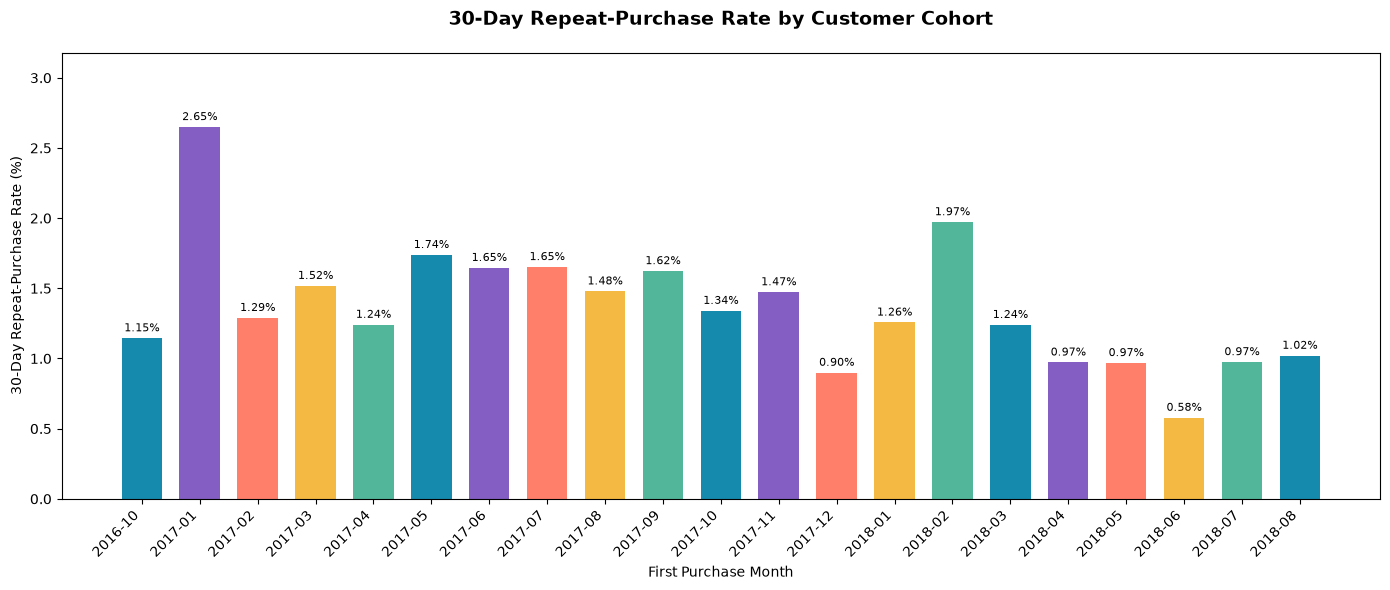

In [89]:
import matplotlib.pyplot as plt

cohort_labels = cohort_30day_rate_filtered.index.astype(str)
cohort_values = cohort_30day_rate_filtered.values

cohort_colors = [
    "#168AAD",  # Teal
    "#845EC2",  # Purple
    "#FF7F6A",  # Coral
    "#F4B942",  # Gold
    "#52B69A"   # Green
]

bar_colors = [
    cohort_colors[i % len(cohort_colors)]
    for i in range(len(cohort_values))
]

plt.figure(figsize=(14, 6))

bars = plt.bar(
    cohort_labels,
    cohort_values,
    color=bar_colors,
    width=0.7
)

plt.bar_label(
    bars,
    labels=[f"{value:.2f}%" for value in cohort_values],
    padding=3,
    fontsize=8
)

plt.title(
    "30-Day Repeat-Purchase Rate by Customer Cohort",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.xlabel("First Purchase Month")
plt.ylabel("30-Day Repeat-Purchase Rate (%)")

plt.xticks(rotation=45, ha="right")
plt.ylim(0, max(cohort_values) * 1.2)
plt.grid(False)

plt.tight_layout()
plt.show()

In [90]:
total_eligible_customers = eligible_cohort_sizes.sum()
total_30day_returns = cohort_30day_returns.sum()

overall_30day_rate = (
    total_30day_returns / total_eligible_customers
) * 100

print("Eligible customers:", total_eligible_customers)
print("Customers returning within 30 days:", total_30day_returns)
print(f"Overall 30-day repeat-purchase rate: {overall_30day_rate:.2f}%")

Eligible customers: 87508
Customers returning within 30 days: 1133
Overall 30-day repeat-purchase rate: 1.29%


### 30-Day Customer Cohort Analysis — Key Findings

This analysis examines second delivered purchases within 30 days of customers' first recorded delivered purchase, grouped by first-purchase month.

**Methodology**

- Customers were assigned to cohorts based on the month of their first recorded delivered purchase.
- An observation cutoff of 31 August 2018 was applied.
- Only customers with a complete 30-day follow-up window were included in the denominator.
- Cohorts with fewer than 100 eligible customers were excluded from the visual comparison, but retained in the overall calculation.

**Key findings**

- **87,508 customers** qualified for the 30-day follow-up analysis.
- **1,133 customers** made a second delivered purchase within 30 days.
- The overall eligible-customer 30-day repeat-purchase rate was **1.29%**.
- Monthly cohort rates varied, including January 2017 at 2.65%, February 2018 at 1.97%, and June 2018 at 0.58%.

**Business interpretation**

A fixed 30-day observation window provides a more consistent basis for comparing customer cohorts than unrestricted historical repeat-purchase rates.

The results suggest variation in observed early repeat purchasing across cohorts, but do not establish why that variation occurred.

**Analytical limitations**

- The measure includes rapid second orders, which may have been placed during the same shopping session.
- The 30-day observation window is based on the chosen dataset cutoff and does not guarantee complete transaction capture.
- Small cohorts produce less stable estimates.
- The analysis measures observed repeat purchasing, not customer satisfaction or loyalty.

**Key takeaway:** Cohort comparisons should account for observation time and sample size before drawing conclusions about changes in customer retention.

In [91]:
customers_returning_1_to_30_days = (
    customer_purchase_history.loc[
        (
            customer_purchase_history["customer_unique_id"]
            .isin(eligible_customer_ids)
        )
        & (
            customer_purchase_history["days_since_first_purchase"] >= 1
        )
        & (
            customer_purchase_history["days_since_first_purchase"] <= 30
        )
        & (
            customer_purchase_history["order_purchase_timestamp"]
            <= observation_end
        ),
        "customer_unique_id"
    ].nunique()
)

print(
    "Eligible customers returning between 1 and 30 days:",
    customers_returning_1_to_30_days
)

Eligible customers returning between 1 and 30 days: 555


In [92]:
return_rate_1_to_30_days = (
    customers_returning_1_to_30_days
    / total_eligible_customers
) * 100

print(f"1–30 day customer return rate: {return_rate_1_to_30_days:.2f}%")

1–30 day customer return rate: 0.63%


In [93]:
eligible_returns_1_to_30 = customer_purchase_history[
    customer_purchase_history["customer_unique_id"].isin(eligible_customer_ids)
    & customer_purchase_history["days_since_first_purchase"].between(1, 30)
    & (customer_purchase_history["order_purchase_timestamp"] <= observation_end)
]

cohort_returns_1_to_30 = (
    eligible_returns_1_to_30
    .groupby("first_purchase_month")["customer_unique_id"]
    .nunique()
)

cohort_rate_1_to_30 = (
    cohort_returns_1_to_30
    .reindex(eligible_cohort_sizes.index, fill_value=0)
    .div(eligible_cohort_sizes)
    .mul(100)
)

cohort_rate_1_to_30.round(2)

first_purchase_month
2016-09      0.00
2016-10      0.00
2016-12    100.00
2017-01      0.56
2017-02      0.61
2017-03      0.48
2017-04      0.66
2017-05      0.87
2017-06      0.53
2017-07      0.69
2017-08      0.62
2017-09      0.87
2017-10      0.58
2017-11      0.74
2017-12      0.37
2018-01      0.54
2018-02      0.54
2018-03      0.59
2018-04      0.71
2018-05      0.77
2018-06      0.49
2018-07      0.76
2018-08      0.68
Freq: M, Name: customer_unique_id, dtype: float64

In [94]:
comparison_cohorts = eligible_cohort_sizes[
    eligible_cohort_sizes >= 100
].index

cohort_comparison = pd.DataFrame({
    "Second purchase within 30 days": cohort_30day_rate.reindex(comparison_cohorts),
    "Any later purchase (1–30 days)": cohort_rate_1_to_30.reindex(comparison_cohorts)
})

cohort_comparison.round(2)

,Second purchase within 30 days,Any later purchase (1–30 days)
first_purchase_month,,
2016-10,1.15,0.00
2017-01,2.65,0.56
2017-02,1.29,0.61
2017-03,1.52,0.48
2017-04,1.24,0.66
2017-05,1.74,0.87
2017-06,1.65,0.53
2017-07,1.65,0.69
2017-08,1.48,0.62


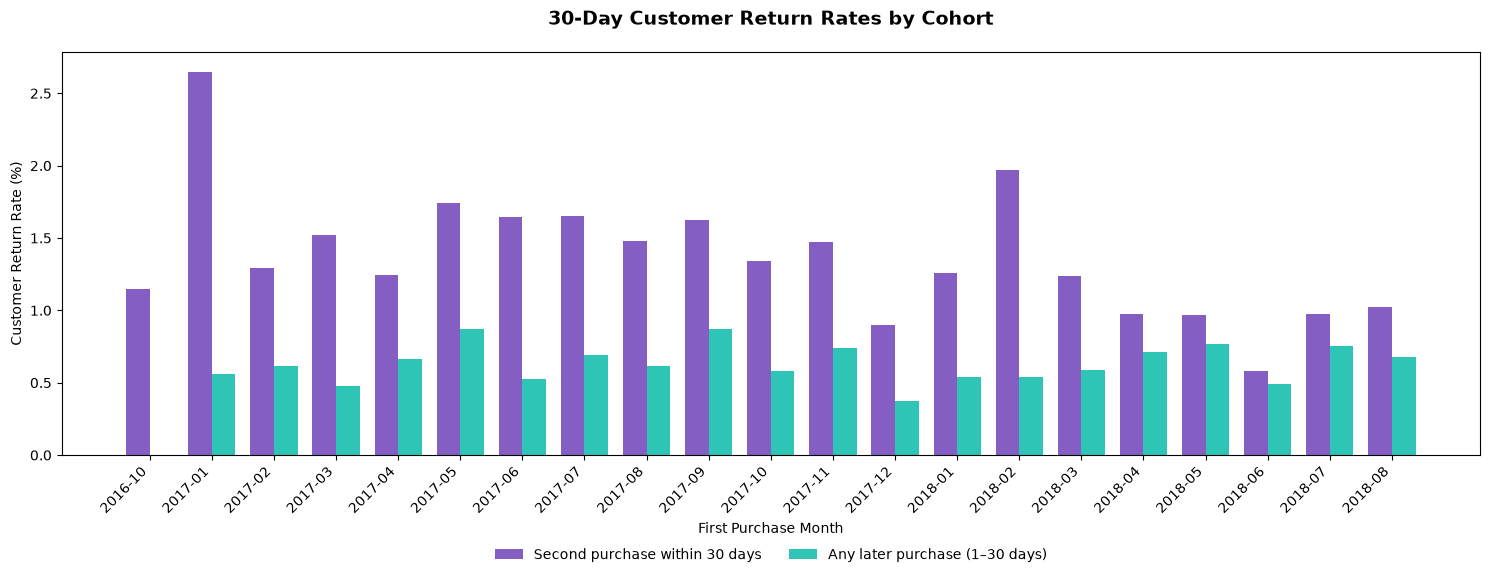

In [96]:
import numpy as np

cohort_labels = cohort_comparison.index.astype(str)
x = np.arange(len(cohort_labels))
width = 0.38

fig, ax = plt.subplots(figsize=(15, 6))

ax.bar(
    x - width / 2,
    cohort_comparison["Second purchase within 30 days"],
    width,
    color="#845EC2",
    label="Second purchase within 30 days"
)

ax.bar(
    x + width / 2,
    cohort_comparison["Any later purchase (1–30 days)"],
    width,
    color="#2EC4B6",
    label="Any later purchase (1–30 days)"
)

ax.set_title(
    "30-Day Customer Return Rates by Cohort",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("First Purchase Month")
ax.set_ylabel("Customer Return Rate (%)")

ax.set_xticks(x)
ax.set_xticklabels(cohort_labels, rotation=45, ha="right")

ax.legend(frameon=False)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.20),
    ncol=2,
    frameon=False
)

plt.tight_layout()
plt.show()

### Comparing 30-Day Customer Return Definitions

This analysis compares two measures of early repeat purchasing across customer acquisition cohorts.

**Measures compared**

- **Second purchase within 30 days:** Percentage of eligible customers whose second delivered order occurred more than zero and no later than 30 days after their first.
- **Any subsequent purchase between 1 and 30 days:** Percentage of eligible customers with at least one additional delivered order between 24 hours and 30 days after their first.

**Key findings**

- The overall second-purchase-within-30-days rate was **1.29%** (1,133 of 87,508 eligible customers).
- The overall 1–30-day subsequent-purchase rate was **0.63%** (555 of 87,508 eligible customers).
- The two measures show different patterns across acquisition cohorts.
- The second-purchase measure is generally higher, partly because it includes rapid repeat orders placed within 24 hours.

**Business interpretation**

Repeat-order frequency and return purchasing after a minimum time interval capture different aspects of customer behaviour.

Using both measures gives a more nuanced view of early purchasing activity than relying on a single repeat-customer rate.

**Limitations**

- The measures overlap and should not be treated as mutually exclusive customer groups.
- A 24-hour threshold does not confirm a separate shopping session.
- Cohort comparisons remain subject to differences in customer mix, sample size and historical data coverage.
- The analysis is descriptive and does not establish why customers return.

**Key takeaway:** Defining return behaviour carefully is essential for interpreting cohort retention metrics and making meaningful business comparisons.

In [97]:
return_thresholds = [1, 7, 30]

print("Return thresholds to investigate:", return_thresholds)

Return thresholds to investigate: [1, 7, 30]


In [98]:
sensitivity_population = first_purchases[
    first_purchases["has_30_day_followup"]
].copy()

print(
    "Customers in sensitivity analysis:",
    len(sensitivity_population)
)

Customers in sensitivity analysis: 87508


In [99]:
first_purchases["has_60_day_followup"] = (
    first_purchases["order_purchase_timestamp"]
    + pd.Timedelta(days=60)
    <= observation_end
)

first_purchases["has_60_day_followup"].value_counts()

has_60_day_followup
True     81608
False    11750
Name: count, dtype: int64

In [100]:
sensitivity_population = first_purchases[
    first_purchases["has_60_day_followup"]
].copy()

print(
    "Eligible customers for 60-day analysis:",
    len(sensitivity_population)
)

Eligible customers for 60-day analysis: 81608


In [101]:
eligible_customer_ids_60 = sensitivity_population[
    "customer_unique_id"
]

purchases_within_60_days = customer_purchase_history[
    customer_purchase_history["customer_unique_id"].isin(
        eligible_customer_ids_60
    )
    & customer_purchase_history["days_since_first_purchase"].between(
        0, 60
    )
    & (customer_purchase_history["purchase_number"] >= 2)
].copy()

print(
    "Additional delivered orders within 60 days:",
    len(purchases_within_60_days)
)

Additional delivered orders within 60 days: 1685


In [102]:
threshold_results = {}

for days in return_thresholds:
    returning_customers = purchases_within_60_days.loc[
        purchases_within_60_days["days_since_first_purchase"] >= days,
        "customer_unique_id"
    ].nunique()

    return_rate = (
        returning_customers / len(sensitivity_population)
    ) * 100

    threshold_results[days] = {
        "customers": returning_customers,
        "return_rate": round(return_rate, 2)
    }

threshold_results

{1: {'customers': 810, 'return_rate': 0.99},
 7: {'customers': 671, 'return_rate': 0.82},
 30: {'customers': 317, 'return_rate': 0.39}}

In [103]:
print(
    "Threshold counts follow expected order:",
    threshold_results[1]["customers"]
    >= threshold_results[7]["customers"]
    >= threshold_results[30]["customers"]
)

print(
    "All threshold counts are within the eligible population:",
    all(
        result["customers"] <= len(sensitivity_population)
        for result in threshold_results.values()
    )
)

Threshold counts follow expected order: True
All threshold counts are within the eligible population: True


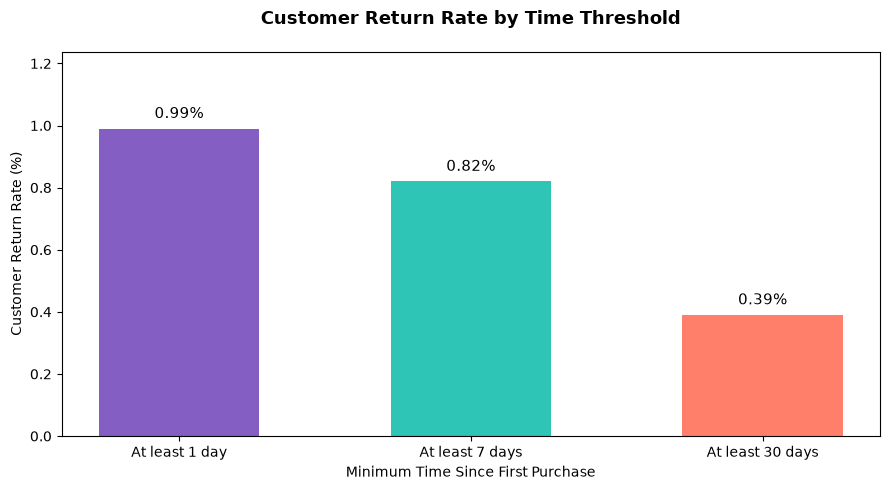

In [105]:
threshold_labels = ["At least 1 day", "At least 7 days", "At least 30 days"]

threshold_rates = [
    threshold_results[1]["return_rate"],
    threshold_results[7]["return_rate"],
    threshold_results[30]["return_rate"]
]

threshold_colors = [
    "#845EC2",  # Purple
    "#2EC4B6",  # Turquoise
    "#FF7F6A"   # Coral
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    threshold_labels,
    threshold_rates,
    color=threshold_colors,
    width=0.55
)

plt.bar_label(
    bars,
    labels=[f"{rate:.2f}%" for rate in threshold_rates],
    padding=5,
    fontsize=11
)

plt.title(
    "Customer Return Rate by Time Threshold",
    fontsize=13,
    fontweight="bold",
    pad=20
)

plt.xlabel("Minimum Time Since First Purchase")
plt.ylabel("Customer Return Rate (%)")

plt.ylim(0, max(threshold_rates) * 1.25)
plt.grid(False)

plt.tight_layout()
plt.show()

### Customer Return Rate Sensitivity Analysis — Key Findings

This analysis examines how different minimum time intervals between purchases affect observed customer return rates.

**Methodology**

- Included **81,608 customers** with a complete 60-day observation window after their first recorded delivered purchase.
- Used 31 August 2018 as the observation cutoff.
- Examined all subsequent delivered purchases within 60 days of each customer's first purchase.
- Applied minimum elapsed-time thresholds of 1, 7 and 30 days.
- Counted each qualifying customer once per threshold.

**Results**

| Minimum purchase interval | Returning customers | Return rate |
|---|---:|---:|
| At least 1 day | 810 | 0.99% |
| At least 7 days | 671 | 0.82% |
| At least 30 days | 317 | 0.39% |

**Business interpretation**

Observed customer return rates vary depending on the minimum time interval required between purchases.

A longer minimum interval produces a lower measured rate because fewer purchases meet the qualifying criteria.

This demonstrates why retention metrics should have clearly documented definitions.

**Limitations**

- The three groups overlap and should not be added together.
- The analysis uses a fixed 60-day observation window and does not measure lifetime retention.
- A minimum time interval does not establish customer satisfaction or loyalty.
- Customers may make additional purchases after the observation window.
- The results are descriptive and do not establish why customers return.

**Key takeaway:** Customer return rates are sensitive to their operational definitions. Comparing results requires consistent populations, observation windows and qualifying purchase conditions.